> **Legacy.** This notebook reads the event-segmented review samples (`review_events_json`) and artifacts built from them, not the detail-segmented stories used by the current experiments. See `docs/data_lineage.md`.

# Quick feature visualization
Loads `results/features/eda/text_features.csv` and plots simple relationships between age and features.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


In [2]:
from pathlib import Path

# Prefer review_samples features if present
candidates = [
    Path('results/features/eda/text_features_batch1_review_samples.csv'),
    Path('../results/features/eda/text_features_batch1_review_samples.csv'),
    Path('results/features/eda/text_features_batch1.csv'),
    Path('../results/features/eda/text_features_batch1.csv'),
    Path('results/features/eda/text_features.csv'),
    Path('../results/features/eda/text_features.csv'),
]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError('Could not find results/features/eda/text_features*.csv (run analysis first)')
df = pd.read_csv(path, low_memory=False)
print('Loaded:', path, df.shape)
df.head(2)


Loaded: ../results/features/eda/text_features_batch1_review_samples.csv (378, 96)


,item_id,story_id,age_lo,age_hi,age_mid,review_n_events,Title,Author,Categories,Num Reviews,...,concept_event_type_counts_json,concept_event_type_seq,concept_event_type_unique,concept_event_type_entropy,concept_mean_event_words,concept_std_event_words,concept_median_event_words,concept_min_event_words,concept_max_event_words,concept_mean_event_sentences
0,T7nVgn9qBJs,10265,4.0,8.0,6.0,11.0,The Moon Keeper: A Moving Picture Book About a...,Zosienka,Books > Children's Books > Growing Up & Facts ...,65.0,...,"{""exposition"": 1, ""initiatingevent"": 1, ""risin...",exposition>initiatingevent>risingaction>rising...,6,1.420572,43.727273,14.078293,44.0,26.0,72.0,4.181818
1,oeYAT8C2BZA,10365,4.0,8.0,6.0,12.0,Alejandro's Gift (Rise and Shine),"Richard E. Albert, Sylvia Long",Kindle Store > Kindle eBooks > Children's eBoo...,69.0,...,"{""exposition"": 1, ""initiatingevent"": 1, ""risin...",exposition>initiatingevent>risingaction>rising...,6,1.349792,50.583333,21.289506,45.0,23.0,92.0,3.500000


## Clean + basic filters

In [3]:
# Keep rows with an age midpoint
d = df.copy()
d['age_mid'] = pd.to_numeric(d.get('age_mid'), errors='coerce')
d = d[d['age_mid'].notna()].copy()

# Numeric amazon fields (if present)
for c in ['Num Reviews','Average Rating','Price','yt_view_count','yt_like_count','yt_duration']:
    if c in d.columns:
        d[c] = pd.to_numeric(d[c], errors='coerce')

print('rows w/ age_mid:', len(d))
d[['age_mid','num_words','mean_sentence_length_words','mean_word_length_chars']].describe()

rows w/ age_mid: 333


,age_mid,num_words,mean_sentence_length_words,mean_word_length_chars
count,333.000000,333.000000,333.000000,333.000000
mean,5.157658,801.324324,13.505230,4.115052
std,1.512969,580.290717,21.223742,0.238794
min,2.000000,50.000000,4.125000,3.214058
25%,4.000000,419.000000,8.985714,3.972727
50%,5.000000,643.000000,10.486486,4.107280
75%,6.000000,1021.000000,13.058824,4.255319
max,10.500000,3707.000000,295.000000,4.720000


## Scatter: age vs basic text features

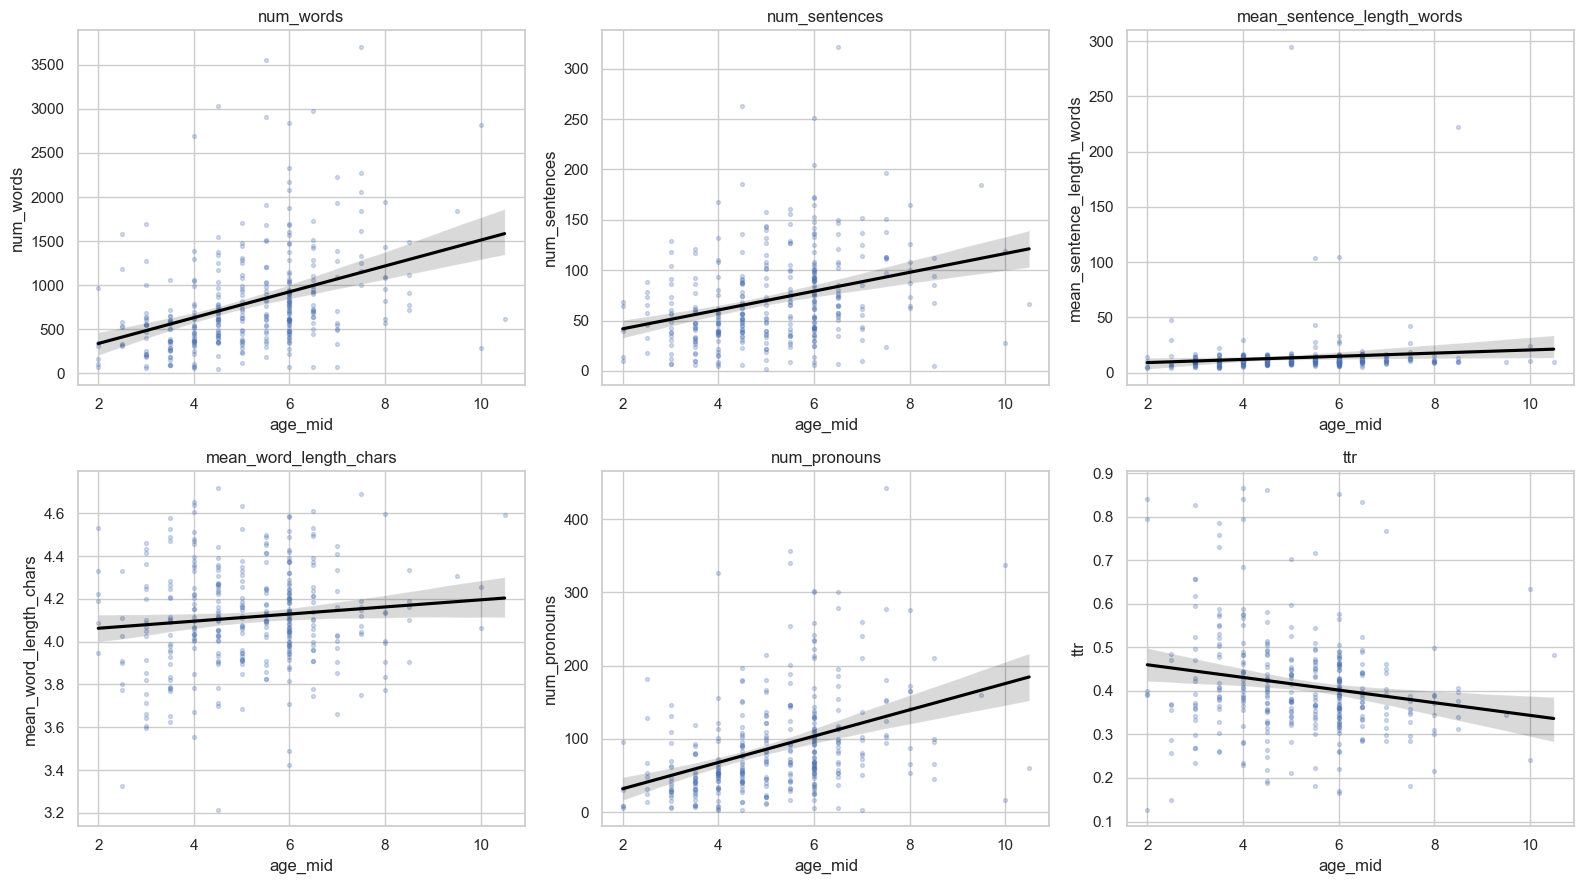

In [4]:
features = [
    'num_words',
    'num_sentences',
    'mean_sentence_length_words',
    'mean_word_length_chars',
    'num_pronouns',
    'ttr',
    'mean_log10_corpus_freq',
    'rare_frac_corpus_le_5',
    'flesch_kincaid_grade_est',
    'avg_syllables_per_word',
    'concept_n_events_parsed',
    'concept_mean_event_words',
]
features = [f for f in features if f in d.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, f in zip(axes, features):
    sns.regplot(data=d, x='age_mid', y=f, ax=ax, scatter_kws={'s':8, 'alpha':0.25}, line_kws={'color':'black'})
    ax.set_title(f)
plt.tight_layout()


## Boxplots by coarse age bins

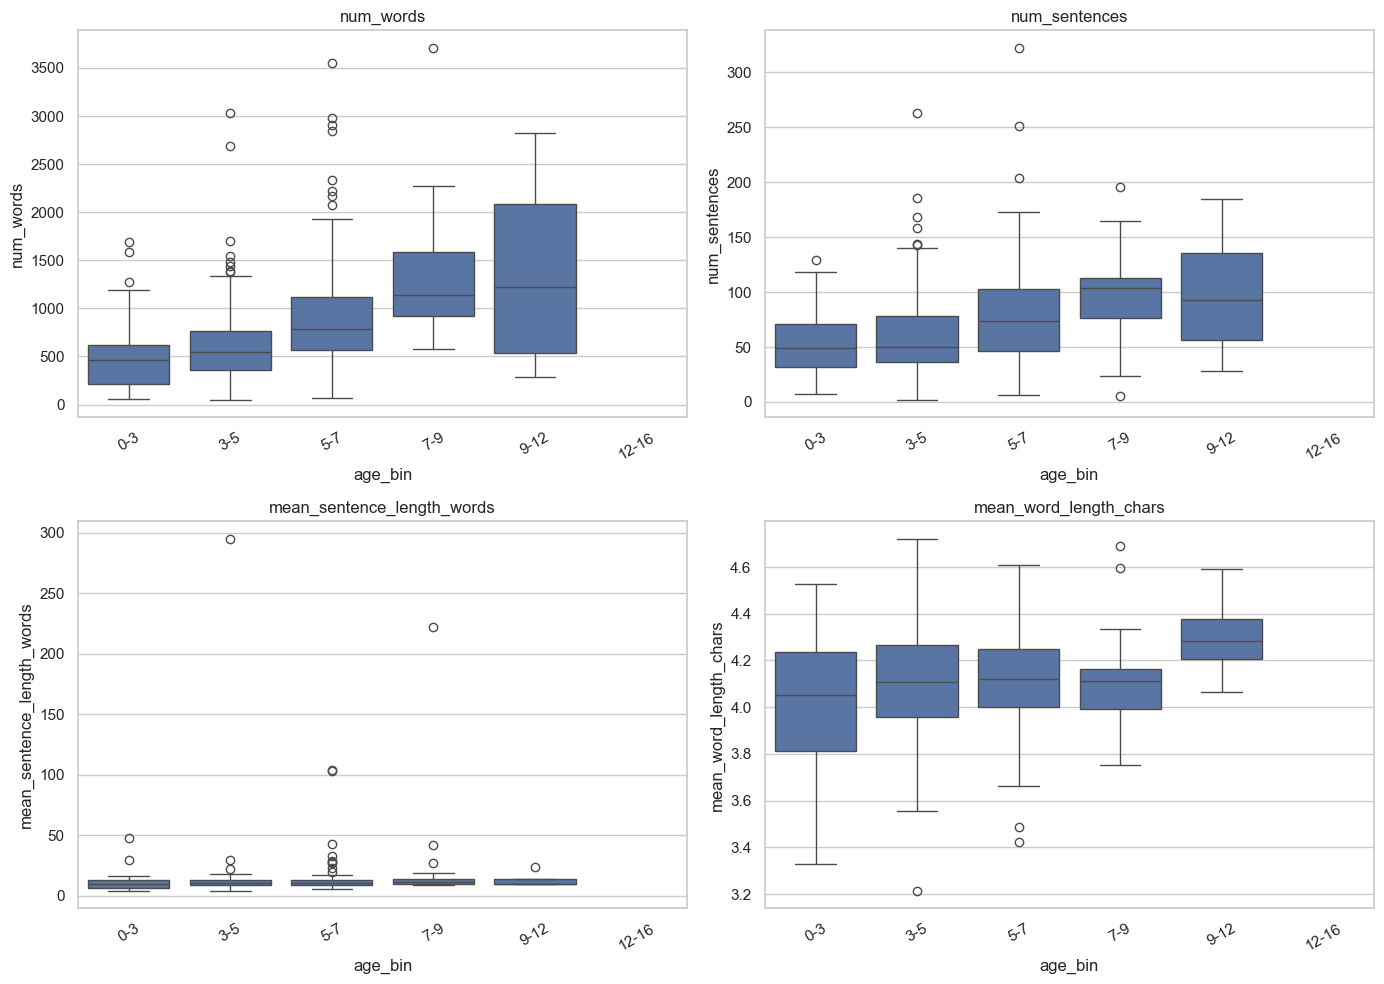

In [5]:
bins = [0, 3, 5, 7, 9, 12, 16]
labels = [f'{bins[i]}-{bins[i+1]}' for i in range(len(bins)-1)]
d['age_bin'] = pd.cut(d['age_mid'], bins=bins, labels=labels, include_lowest=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for ax, f in zip(axes, features[:4]):
    sns.boxplot(data=d, x='age_bin', y=f, ax=ax)
    ax.set_title(f)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()


## Amazon popularity/ratings (if present)

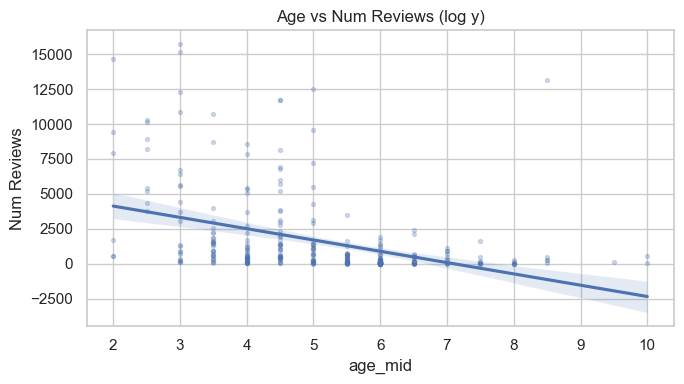

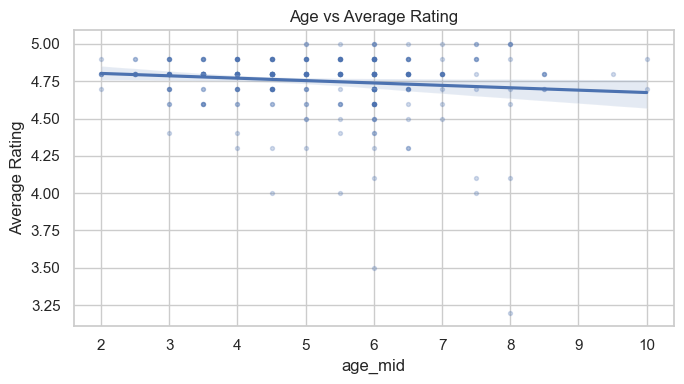

In [8]:
if 'Num Reviews' in d.columns:
    plt.figure(figsize=(7,4))
    sns.regplot(data=d, x='age_mid', y='Num Reviews', scatter_kws={'s':8,'alpha':0.25})
    # plt.yscale('log')
    plt.title('Age vs Num Reviews (log y)')
    plt.tight_layout()

if 'Average Rating' in d.columns:
    plt.figure(figsize=(7,4))
    sns.regplot(data=d, x='age_mid', y='Average Rating', scatter_kws={'s':8,'alpha':0.25})
    plt.title('Age vs Average Rating')
    plt.tight_layout()


## Category breakdown (top categories)

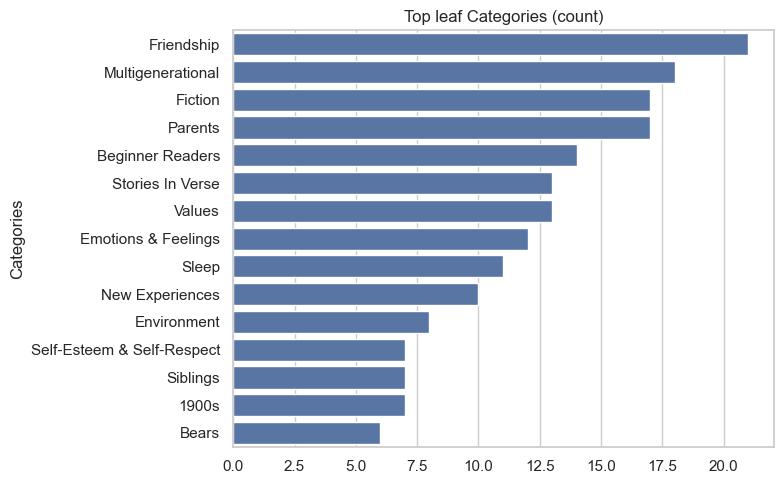

In [7]:
if 'Categories' in d.columns:
    # Take the last breadcrumb after '>' as a simple leaf category
    leaf = d['Categories'].astype(str).str.split('>').str[-1].str.strip()
    vc = leaf.value_counts().head(15)
    plt.figure(figsize=(8,5))
    sns.barplot(x=vc.values, y=vc.index)
    plt.title('Top leaf Categories (count)')
    plt.tight_layout()
    vc

## Corpus Word Frequency (whole corpus)

This recomputes corpus-level word frequencies from the master file (review_events text if available) and plots a Zipf curve + distribution of log token frequencies.

If you don't have the master locally, this section will error; pull/copy `data/processed/master_batch1.csv.gz` first.


Loaded master: /Users/tzl/repos/story-features/data/processed/master_batch1.csv.gz (2860, 551)
docs: 0 total tokens: 0 types: 0


ValueError: Data has no positive values, and therefore cannot be log-scaled.

Error in callback <function _draw_all_if_interactive at 0x11d632b90> (for post_execute), with arguments args (),kwargs {}:


ValueError: Data has no positive values, and therefore cannot be log-scaled.

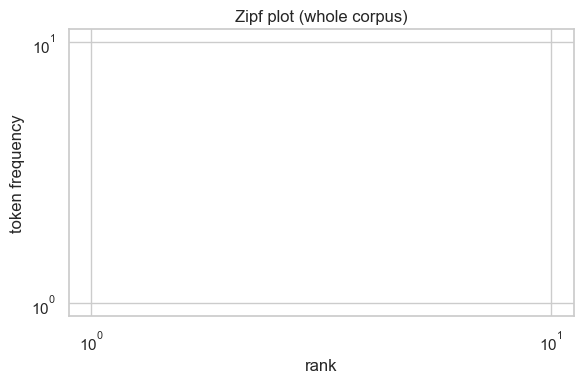

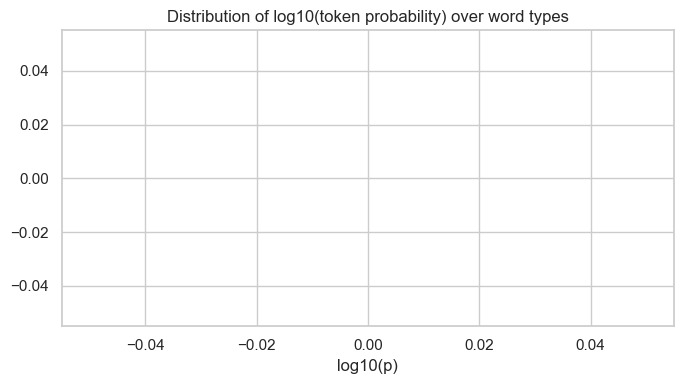

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 700x400 with 1 Axes>

In [9]:
import re
from collections import Counter
from pathlib import Path

def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / 'data' / 'processed').exists():
            return p
    return here

ROOT = find_repo_root()
master_candidates = [
    ROOT / 'data/processed/master_batch1.csv.gz',
    ROOT / 'data/processed/master_batch1.parquet',
    ROOT / 'data/processed/master_stories.csv.gz',
    ROOT / 'data/processed/master_stories.parquet',
]
mpath = next((p for p in master_candidates if p.exists()), None)
if mpath is None:
    raise FileNotFoundError(f'No master found under {ROOT}/data/processed/')

if mpath.suffix == ".parquet":
    m = pd.read_parquet(mpath)
else:
    m = pd.read_csv(mpath, low_memory=False)
print("Loaded master:", mpath, m.shape)

# Prefer review event text (matches your feature pipeline)
def _safe_json_loads(x):
    if x is None: return None
    try:
        import numpy as np
        if isinstance(x, float) and np.isnan(x):
            return None
    except Exception:
        pass
    if isinstance(x, (dict, list)):
        return x
    s = str(x).strip()
    if not s or s.lower()=="nan":
        return None
    try:
        return json.loads(s)
    except Exception:
        return None

def review_events_text(x):
    evs = _safe_json_loads(x)
    if not isinstance(evs, list):
        return None
    parts=[]
    for e in evs:
        if not isinstance(e, dict):
            continue
        sents = e.get("sentences")
        if not isinstance(sents, list):
            continue
        for s in sents:
            if isinstance(s, dict) and "text" in s:
                parts.append(str(s["text"]))
            elif isinstance(s, str):
                parts.append(s)
    txt = " ".join(p.strip() for p in parts if p and str(p).strip()).strip()
    return txt if txt else None

text_col = None
if "review_events_json" in m.columns:
    text_col = "review_events_json"
    texts = m[text_col].apply(review_events_text)
    texts = texts[texts.notna()].astype(str).tolist()
else:
    # fallback to transcript_best if present
    for c in ["transcript_best","yt_cleaned_subtitles","transcript_txt"]:
        if c in m.columns:
            text_col = c
            texts = m[c].dropna().astype(str).tolist()
            break
    if text_col is None:
        raise ValueError("No usable text column found in master")

WORD_RE = re.compile(r"[A-Za-z']+")
counts = Counter()
total = 0
for t in texts:
    toks = [w.lower() for w in WORD_RE.findall(t)]
    total += len(toks)
    counts.update(toks)
print("docs:", len(texts), "total tokens:", total, "types:", len(counts))

# Zipf curve: rank vs frequency
freqs = np.array(sorted(counts.values(), reverse=True), dtype=float)
ranks = np.arange(1, len(freqs)+1)
plt.figure(figsize=(6,4))
plt.loglog(ranks, freqs)
plt.xlabel("rank")
plt.ylabel("token frequency")
plt.title("Zipf plot (whole corpus)")
plt.tight_layout()

# Distribution of log10 token probability across tokens (type-weighted)
p = freqs / freqs.sum()
plt.figure(figsize=(7,4))
sns.histplot(np.log10(p + 1e-12), bins=60)
plt.title("Distribution of log10(token probability) over word types")
plt.xlabel("log10(p)")
plt.tight_layout()


# Distribution of raw word counts across types (corpus-wide)
plt.figure(figsize=(7,4))
sns.histplot(freqs, bins=80)
plt.yscale('log')
plt.xscale('log')
plt.title('Distribution of word counts across types (log-log)')
plt.xlabel('count(word)')
plt.ylabel('# word types')
plt.tight_layout()

# Counts-of-counts: how many types appear exactly k times (k=1..20)
from collections import Counter
coc = Counter(freqs.astype(int).tolist())
xs = list(range(1, 21))
ys = [coc.get(k, 0) for k in xs]
plt.figure(figsize=(8,4))
sns.barplot(x=xs, y=ys)
plt.yscale('log')
plt.title('Counts-of-counts: #types with frequency=k')
plt.xlabel('k')
plt.ylabel('# word types (log)')
plt.tight_layout()

# Cumulative token coverage by top-ranked words
cum = np.cumsum(freqs) / freqs.sum()
plt.figure(figsize=(6,4))
plt.plot(ranks, cum)
plt.xscale('log')
plt.title('Cumulative token coverage vs rank')
plt.xlabel('rank (log)')
plt.ylabel('fraction of tokens covered')
plt.tight_layout()

# Top words by count
topn = 20
top_items = counts.most_common(topn)
plt.figure(figsize=(10,4))
sns.barplot(x=[w for w,_ in top_items], y=[c for _,c in top_items])
plt.xticks(rotation=40, ha='right')
plt.title(f'Top {topn} word types by count (whole corpus)')
plt.ylabel('count')
plt.tight_layout()
